# Chapter 17: Context, Framing, Salience, and Choice Architecture

This notebook reruns four worked examples from the chapter: a fund menu that discourages enrollment (choice overload), a salient upside that flips a lottery choice (salience theory), the 70,000 mile price cliff (left-digit bias), and enrollment under different defaults (default effect). Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def choice_overload_net(benefit, match, hours, wage, regret):
    """choice-overload: net enrollment value = benefit + match - hours x wage - regret.

    Book (ch017): 1,000 + 600 - 200 - 50 = 1,350; 1,100 + 600 - 600 - 150 = 950;
    1,100 + 600 - 200 - 75 = 1,425.
    """
    return float(benefit + match - hours * wage - regret)


def salience_contrast(payoff, reference):
    """salience-theory: proportional contrast |x - r| / (x + r). Book (ch017): 130/230 = 0.565, 15/85 = 0.176."""
    return abs(payoff - reference) / (payoff + reference)


def salience_weights(probs, payoffs, reference, delta):
    """salience-theory: rank states by contrast with the reference; the k-th ranked state's
    probability is multiplied by delta**(k-1), then weights are normalized.

    Book (ch017): p = (0.10, 0.90), payoffs (180, 35), reference 50, delta 0.7 gives
    pi_H = 0.10 / (0.10 + 0.90 x 0.7) = 0.137. Ties in contrast share a rank.
    """
    contrasts = [salience_contrast(x, reference) for x in payoffs]
    order = sorted(set(contrasts), reverse=True)
    raw = [p * delta ** order.index(c) for p, c in zip(probs, contrasts)]
    total = sum(raw)
    return [r / total for r in raw]


def salience_value(probs, payoffs, reference, delta):
    """salience-theory: salience-weighted value with linear utility. Book (ch017): 0.137(180) + 0.863(35) = 54.86."""
    w = salience_weights(probs, payoffs, reference, delta)
    return sum(wi * x for wi, x in zip(w, payoffs))


def left_digit_value(miles, base_value, base_miles, rate, threshold, penalty):
    """left-digit-bias: perceived value = base_value - rate x (miles - base_miles), minus the
    category penalty once miles reach the round-number threshold.

    Book (ch017): 15,000 - 200(0.10) = 14,980; 14,980 - 500 = 14,480 at 70,100 miles.
    """
    smooth = base_value - rate * (miles - base_miles)
    return float(smooth - (penalty if miles >= threshold else 0))


def default_enrollment(groups, default, switch_cost, active_choice=False):
    """default-effect: enrolled count for groups of (count, delta, attentive, prompted_delta).

    Attentive workers leave the default only when the gain from switching exceeds the
    switching cost. Inattentive workers keep the default, unless active choice is required,
    when they decide on prompted_delta. Under active choice nobody has a default to leave, so
    each worker enrolls when delta > 0. Book (ch017): 60, 100 and 69 of 100 workers.
    """
    enrolled = 0
    for count, delta, attentive, prompted in groups:
        if active_choice:
            d = delta if attentive else prompted
            enrolled += count if d > 0 else 0
        elif not attentive:
            enrolled += count if default == "enroll" else 0
        elif default == "enroll":
            enrolled += count if -delta <= switch_cost else 0
        else:
            enrolled += count if delta > switch_cost else 0
    return enrolled


plt.rcParams.update(HOUSE_RC)


behavioral = SimpleNamespace(choice_overload_net=choice_overload_net, salience_contrast=salience_contrast, salience_weights=salience_weights, salience_value=salience_value, left_digit_value=left_digit_value, default_enrollment=default_enrollment)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'choice-overload': {'match': 600,
                     'wage': 100,
                     'outside': 1250,
                     'menus': {'six': {'benefit': 1000, 'hours': 2, 'regret': 50, 'net': 1350},
                               'thirty': {'benefit': 1100, 'hours': 6, 'regret': 150, 'net': 950},
                               'tool': {'benefit': 1100, 'hours': 2, 'regret': 75, 'net': 1425}},
                     'benefit_rise': 100,
                     'burden_rise': 500},
 'salience-theory': {'sure': 50,
                     'high': 180,
                     'p_high': 0.1,
                     'low': 35,
                     'delta': 0.7,
                     'ev': 49.5,
                     'contrast_high': 0.565,
                     'contrast_low': 0.176,
                     'pi_H': 0.137,
                     'pi_L': 0.863,
                     'value': 54.86},
 'left-digit-bias': {'value_A': 15000,
                     'miles_A': 69900,
                     'miles_B': 70100,
                     'rate': 0.1,
                     'threshold': 70000,
                     'penalty': 500,
                     'benchmark_B': 14980,
                     'perceived_B': 14480,
                     'gap': 520},
 'default-effect': {'favorable': 60,
                    'delta_fav': 30,
                    'unfavorable': 25,
                    'delta_unf': -10,
                    'inattentive': 15,
                    'prompted_fav': 9,
                    'prompted_unf': 6,
                    'switch_cost': 20,
                    'opt_in': 60,
                    'auto_enroll': 100,
                    'active': 69},
 'constructed': {'choice-overload': {'hours': [4]},
                 'salience-theory': {'delta': [0.5, 0.85], 'high': [150, 220]},
                 'left-digit-bias': {'miles_B': [69950, 70500], 'penalty': [0, 250, 750]},
                 'default-effect': {'switch_cost': [5, 40]}}}


MENUS = {"six": "6 funds", "thirty": "30 funds", "tool": "30 funds with screening tool"}


REGIMES = {"opt_in": "Opt-in (not enrolled by default)", "auto": "Automatic enrollment", "active": "Active choice"}


def _groups(bv):
    return [(bv["favorable"], bv["delta_fav"], True, None), (bv["unfavorable"], bv["delta_unf"], True, None),
            (bv["prompted_fav"], None, False, 1), (bv["prompted_unf"], None, False, -1)]


def overload_picture(menu="six", hours=2):
    bv = BV["choice-overload"]
    m = bv["menus"][menu]
    match, wage, outside = bv["match"], bv["wage"], bv["outside"]
    time_cost = hours * wage
    net = behavioral.choice_overload_net(m["benefit"], match, hours, wage, m["regret"])
    verdict, tie = tie_or_winner("enroll", net, "keep cash", outside)
    fig, ax = new_figure()
    stacked_bar(ax, [MENUS[menu]], [[m["benefit"]], [match], [-time_cost], [-m["regret"]]],
                ["portfolio benefit", "employer match", "comparison time", "anticipated regret"],
                colors=["teal", "navy", "terracotta", "gold"], ylabel="Dollars", fmt=lambda v: money(v, 0))
    hline(ax, outside, f"outside option {money(outside, 0)}", col="olive" if net <= outside else "grey", x_frac=0.55)
    ax.set_ylim(-1_100, 2_300)
    ax.legend(loc="lower right", frameon=False)
    ax.set_xlabel("Menu")
    if tie:
        decision = "Enrolling and keeping cash tie"
    else:
        decision = "Maya enrolls" if verdict == "enroll" else "Maya keeps the cash"
    metrics = {"Portfolio benefit": money(m["benefit"], 0), "Time cost": money(time_cost, 0),
               "Anticipated regret": money(m["regret"], 0), "Net enrollment value": money(net, 0),
               "Outside option": money(outside, 0), "Decision": decision}
    decision_lc = decision[0].lower() + decision[1:] if tie else decision
    rel = "equals" if tie else ("exceeds" if net > outside else "falls short of")
    interp = (f"With {MENUS[menu]} and {num(hours, 0)} hours of comparison, time costs {num(hours, 0)} x {num(wage, 0)} = "
              f"{num(time_cost, 0)} dollars and the net value is {num(m['benefit'], 0)} + {num(match, 0)} - {num(time_cost, 0)} - {num(m['regret'], 0)} = "
              f"{money(net, 0)}, which {rel} the {money(outside, 0)} outside option. {decision}.")
    steps = [f"Time cost = {num(hours, 0)} x {num(wage, 0)} = {num(time_cost, 0)}",
             f"Net = {num(m['benefit'], 0)} + {num(match, 0)} - {num(time_cost, 0)} - {num(m['regret'], 0)} = {num(net, 0)}",
             f"Compare with the outside option {num(outside, 0)}: {decision_lc}"]
    alt = (f"A stacked bar for {MENUS[menu]}: benefit {money(m['benefit'], 0)} and match {money(match, 0)} above zero, "
           f"time cost {money(time_cost, 0)} and regret {money(m['regret'], 0)} below. The net {money(net, 0)} is "
           f"marked against a dashed line at the {money(outside, 0)} outside option.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def salience_picture(delta=0.7, high=180):
    bv = BV["salience-theory"]
    sure, p, low = bv["sure"], bv["p_high"], bv["low"]
    probs, pays = [p, 1 - p], [high, low]
    ev = p * high + (1 - p) * low
    c_h = behavioral.salience_contrast(high, sure)
    c_l = behavioral.salience_contrast(low, sure)
    w_h, w_l = behavioral.salience_weights(probs, pays, sure, delta)
    val = behavioral.salience_value(probs, pays, sure, delta)
    winner, tie = tie_or_winner("the lottery L", val, "the sure $50", sure)
    high_first = c_h >= c_l
    fig, ax = new_figure()
    xs = np.arange(2)
    ax.bar(xs - 0.18, [p, 1 - p], width=0.34, color=PALETTE["light"], label="objective probability")
    ax.bar(xs + 0.18, [w_h, w_l], width=0.34, color=PALETTE["teal"], label="salience weight")
    for x, a, b in zip(xs, [p, 1 - p], [w_h, w_l]):
        ax.annotate(num(a, 3), (x - 0.18, a), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10.5)
        ax.annotate(num(b, 3), (x + 0.18, b), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10.5)
    ax.set_xticks(xs, [f"high state ${high}", "low state $35"])
    ax.set_ylim(0, 1.25)
    ax.set_ylabel("Weight")
    ax.set_xlabel("Lottery state")
    ax.legend(loc="upper left", frameon=False)
    ax.text(0.98, 0.97, tex_safe(f"weighted value {money(val)} vs sure {money(sure, 0)}"), transform=ax.transAxes, ha="right",
            va="top", fontsize=10.5, color=PALETTE["ink"])
    choice = "Tie" if tie else ("Lottery L" if winner.startswith("the lottery") else "Sure $50")
    metrics = {"Expected value": money(ev), "Upside contrast": pct(c_h), "Downside contrast": pct(c_l),
               "Weight on high state": num(w_h, 3), "Weighted value": money(val), "Choice": choice}
    if high_first:
        piH = f"pi_H = {num(p, 2)} / ({num(p, 2)} + {num(1 - p, 2)} x {num(delta, 2)}) = {num(w_h, 3)}"
        rank = "The upside is the more salient state, so the downside probability is discounted by delta"
    else:
        piH = f"pi_H = {num(p, 2)} x {num(delta, 2)} / ({num(p, 2)} x {num(delta, 2)} + {num(1 - p, 2)}) = {num(w_h, 3)}"
        rank = "The downside is the more salient state, so the upside probability is discounted by delta"
    decision = ("the two options tie" if tie else f"the chooser takes {winner}")
    interp = (f"Expected value is {num(p, 2)}({high}) + {num(1 - p, 2)}(35) = {money(ev)}. Contrasts are "
              f"({high} - 50)/({high} + 50) = {pct(c_h)} and (50 - 35)/(50 + 35) = {pct(c_l)}. {rank}: {piH}. "
              f"Weighted value = {num(w_h, 6)}({high}) + {num(w_l, 6)}(35) = {money(val)}, so {decision}.")
    steps = [f"EV = {num(p, 2)} x {high} + {num(1 - p, 2)} x 35 = {num(ev)}",
             f"Upside contrast = {high - 50} / {high + 50} = {num(c_h, 4)}; downside = 15 / 85 = {num(c_l, 4)}",
             piH,
             f"Value = {num(w_h, 6)} x {high} + {num(w_l, 6)} x 35 = {num(val)}",
             f"Compare with the sure 50: {decision}"]
    alt = (f"Bars compare objective probabilities 0.10 and 0.90 with salience weights {num(w_h, 3)} and "
           f"{num(w_l, 3)} at delta {num(delta, 2)} and upside {money(high, 0)}. The weighted value is {money(val)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def left_digit_picture(miles_b=70_100, penalty=500):
    bv = BV["left-digit-bias"]
    vA, mA, rate, thr = bv["value_A"], bv["miles_A"], bv["rate"], bv["threshold"]
    bench = behavioral.left_digit_value(miles_b, vA, mA, rate, thr, 0)
    perceived = behavioral.left_digit_value(miles_b, vA, mA, rate, thr, penalty)
    smooth_drop = vA - bench
    gap = vA - perceived
    crossed = miles_b >= thr
    fig, ax = new_figure()
    xs = np.linspace(69_800, 70_600, 400)
    ax.plot(xs, [behavioral.left_digit_value(x, vA, mA, rate, thr, 0) for x in xs], color=PALETTE["grey"],
            linestyle="dashed", linewidth=1.6, label="smooth depreciation")
    left = xs[xs < thr]
    right = xs[xs >= thr]
    ax.plot(left, [behavioral.left_digit_value(x, vA, mA, rate, thr, penalty) for x in left], color=PALETTE["teal"],
            linewidth=2.2, label="perceived value")
    ax.plot(right, [behavioral.left_digit_value(x, vA, mA, rate, thr, penalty) for x in right], color=PALETTE["teal"],
            linewidth=2.2)
    mark(ax, mA, vA, f"A: {money(vA, 0)}", col="navy", dx=8, dy=8)
    mark(ax, miles_b, perceived, f"B: {money(perceived, 0)}", col="terracotta", dx=-8, dy=-12, va="top", ha="right")
    ax.axvline(thr, color=PALETTE["light"], linewidth=1)
    ax.set_xlim(69_800, 70_600)
    ax.set_ylim(13_500, 15_200)
    ax.set_xlabel("Odometer miles")
    ax.set_ylabel("Car value ($)")
    ax.legend(loc="lower right", frameon=False)
    metrics = {"Benchmark value of B": money(bench, 0), "Perceived value of B": money(perceived, 0),
               "Perceived gap from A": money(gap, 0), "Smooth depreciation": money(smooth_drop, 0),
               "Excess discontinuity": money(penalty if crossed else 0, 0)}
    extra_miles = miles_b - mA
    if crossed:
        pen_text = (f"B's odometer reads 70 thousand, so the {money(penalty, 0)} category penalty applies: "
                    f"{num(bench, 0)} - {num(penalty, 0)} = {money(perceived, 0)}")
    else:
        pen_text = "B's odometer still starts with 69, so no category penalty applies"
    interp = (f"B has {num(extra_miles, 0)} more miles than A, so smooth wear lowers its value by {num(extra_miles, 0)} "
              f"x 0.10 = {num(smooth_drop, 0)} dollars, to {money(bench, 0)}. {pen_text}. The perceived gap from A is "
              f"{money(gap, 0)}.")
    steps = [f"Extra miles = {num(miles_b, 0)} - {num(mA, 0)} = {num(extra_miles, 0)}",
             f"Benchmark = 15,000 - {num(extra_miles, 0)} x 0.10 = {num(bench, 0)}",
             (f"Perceived = {num(bench, 0)} - {num(penalty, 0)} = {num(perceived, 0)}" if crossed
              else f"Perceived = {num(bench, 0)} (below 70,000, no penalty)"),
             f"Gap = 15,000 - {num(perceived, 0)} = {num(gap, 0)}"]
    alt = (f"Car value against mileage: a dashed line falling $0.10 per mile and a solid perceived-value line that "
           f"drops by {money(penalty, 0)} at 70,000 miles. Car A at 69,900 miles is worth {money(vA, 0)}; car B at "
           f"{num(miles_b, 0)} miles is perceived at {money(perceived, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def default_picture(regime="opt_in", cost=20):
    bv = BV["default-effect"]
    groups = _groups(bv)
    active = regime == "active"
    default = "enroll" if regime == "auto" else "not"
    per = [behavioral.default_enrollment([g], default, cost, active) for g in groups]
    total = sum(per)
    fig, ax = new_figure()
    kinds = [("teal", "favorable, +$30", per[0], bv["favorable"]), ("terracotta", "unfavorable, -$10", per[1], bv["unfavorable"]),
             ("gold", "inattentive", per[2] + per[3], bv["inattentive"])]
    i = 0
    for col, name, enrolled, count in kinds:
        xs, ys, filled = [], [], []
        for k in range(count):
            xs.append(i % 10)
            ys.append(9 - i // 10)
            filled.append(k < enrolled)
            i += 1
        xs, ys, filled = np.array(xs), np.array(ys), np.array(filled)
        ax.scatter(xs[filled], ys[filled], s=120, color=PALETTE[col], label=f"{name}: {enrolled} of {count} enrolled")
        ax.scatter(xs[~filled], ys[~filled], s=120, facecolors="white", edgecolors=PALETTE[col], linewidths=1.6)
    ax.set_xlim(-0.8, 9.8)
    ax.set_ylim(-4.2, 9.8)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.legend(loc="lower left", frameon=False, ncol=1)
    ax.set_xlabel("Each dot is one worker; filled dots are enrolled")
    ax.set_ylabel("Workers, 10 per row")
    metrics = {"Regime": REGIMES[regime], "Switching cost": money(cost, 0), "Favorable enrolled": f"{per[0]} of 60",
               "Unfavorable enrolled": f"{per[1]} of 25", "Inattentive enrolled": f"{per[2] + per[3]} of 15",
               "Enrollment rate": f"{total}%"}
    if active:
        why = (f"Under active choice every worker must answer and there is no default to leave, so the {money(cost, 0)} "
               f"cost does not tip anyone. The 60 favorable workers and 9 of the 15 newly attentive enroll: 60 + 9 = "
               f"{total}.")
        steps = ["No default: each worker enrolls when the intrinsic gain is positive",
                 "Favorable 60 enroll; unfavorable 25 decline",
                 "Inattentive 15 prompted: 9 favorable enroll, 6 decline",
                 f"Enrollment = 60 + 9 = {total}, so {total}%"]
    elif regime == "opt_in":
        moves = bv["delta_fav"] > cost
        why = (f"With non-enrollment as the default, the favorable workers switch only if $30 exceeds the "
               f"{money(cost, 0)} cost, which it {'does' if moves else 'does not'}. The 25 unfavorable and 15 "
               f"inattentive workers stay out. Enrollment is {per[0]} + 0 + 0 = {total}, or {total}%.")
        steps = [f"Favorable: gain 30 {'>' if moves else '<='} cost {num(cost, 0)}, so {per[0]} enroll",
                 "Unfavorable 25 stay out (enrolling loses 10)",
                 "Inattentive 15 keep the default: out",
                 f"Enrollment = {per[0]} + 0 + 0 = {total}, so {total}%"]
    else:
        leave = -bv["delta_unf"] > cost
        why = (f"With enrollment as the default, the favorable workers stay in. The 25 unfavorable workers gain $10 by "
               f"opting out, {'more' if leave else 'no more'} than the {money(cost, 0)} cost, so they "
               f"{'leave' if leave else 'stay'}. The 15 inattentive workers are enrolled automatically. Enrollment is 60 + {per[1]} + 15 = {total}, or {total}%.")
        steps = ["Favorable 60 stay enrolled",
                 f"Unfavorable: gain from leaving 10 {'>' if leave else '<='} cost {num(cost, 0)}, so {per[1]} stay enrolled",
                 "Inattentive 15 keep the default: enrolled",
                 f"Enrollment = 60 + {per[1]} + 15 = {total}, so {total}%"]
    interp = why
    alt = (f"A grid of 100 dots: 60 favorable, 25 unfavorable and 15 inattentive workers, filled when enrolled. "
           f"Under {REGIMES[regime].lower()} with a {money(cost, 0)} switching cost, {total} of 100 are enrolled.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Choice overload: when more funds means fewer savers

Maya's net enrollment value is portfolio benefit plus a \$600 match, minus comparison hours at \$100 per hour, minus anticipated regret. Keeping the money liquid is worth \$1,250.

$$1{,}000+600-200-50=\$1{,}350, \qquad 1{,}100+600-600-150=\$950, \qquad 1{,}100+600-200-75=\$1{,}425$$

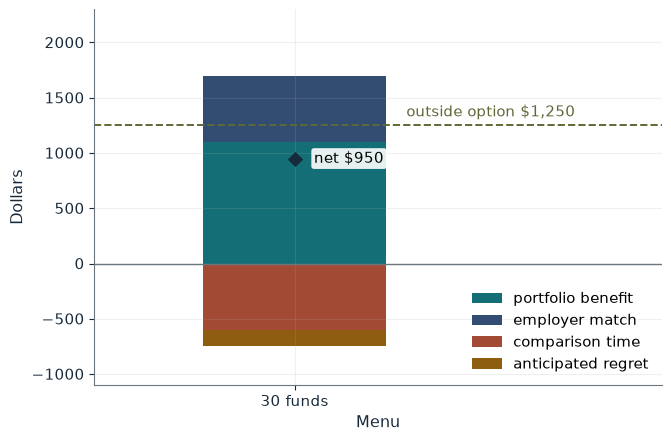

Portfolio benefit     $1,100
Time cost             $600
Anticipated regret    $150
Net enrollment value  $950
Outside option        $1,250
Decision              Maya keeps the cash

Worked steps:
  1. Time cost = 6 x 100 = 600
  2. Net = 1,100 + 600 - 600 - 150 = 950
  3. Compare with the outside option 1,250: Maya keeps the cash

With 30 funds and 6 hours of comparison, time costs 6 x 100 = 600 dollars and the net value is 1,100 + 600 - 600 - 150 = $950, which falls short of the $1,250 outside option. Maya keeps the cash.


In [2]:
show(overload_picture(menu='thirty', hours=6))

Change one input, `hours`, and hold the others at the book's values:

In [3]:
sweep(overload_picture, 'hours', [2, 4, 6], {'menu': 'thirty'}, ['Time cost', 'Net enrollment value', 'Decision'])

hours | Time cost | Net enrollment value | Decision
2 | $200 | $1,350 | Maya enrolls
4 | $400 | $1,150 | Maya keeps the cash
6 | $600 | $950 | Maya keeps the cash


Thirty funds raise the best portfolio benefit by \$100 but, at six hours and \$150 of regret, raise the decision burden by \$500, so the net falls to \$950 and Maya keeps the cash. The screening tool (`menu='tool'`, 2 hours) brings the net to \$1,425 without removing any fund.

## 2. Salience theory: the upside pulls weight

Lottery L pays \$180 with probability 0.10 and \$35 with probability 0.90; the alternative is a sure \$50.

$$0.10(180)+0.90(35)=\$49.50, \qquad \pi_H=\frac{0.10}{0.10+0.90(0.7)}\approx0.137$$

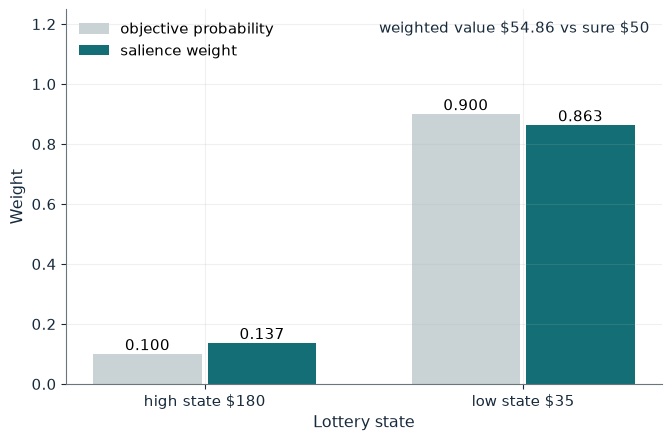

Expected value        $49.50
Upside contrast       56.5%
Downside contrast     17.6%
Weight on high state  0.137
Weighted value        $54.86
Choice                Lottery L

Worked steps:
  1. EV = 0.10 x 180 + 0.90 x 35 = 49.50
  2. Upside contrast = 130 / 230 = 0.5652; downside = 15 / 85 = 0.1765
  3. pi_H = 0.10 / (0.10 + 0.90 x 0.70) = 0.137
  4. Value = 0.136986 x 180 + 0.863014 x 35 = 54.86
  5. Compare with the sure 50: the chooser takes the lottery L

Expected value is 0.10(180) + 0.90(35) = $49.50. Contrasts are (180 - 50)/(180 + 50) = 56.5% and (50 - 35)/(50 + 35) = 17.6%. The upside is the more salient state, so the downside probability is discounted by delta: pi_H = 0.10 / (0.10 + 0.90 x 0.70) = 0.137. Weighted value = 0.136986(180) + 0.863014(35) = $54.86, so the chooser takes the lottery L.


In [4]:
show(salience_picture(delta=0.7, high=180))

Change one input, `delta`, and hold the others at the book's values:

In [5]:
sweep(salience_picture, 'delta', [0.5, 0.7, 0.85, 1.0], {'high': 180}, ['Weight on high state', 'Weighted value', 'Choice'])

delta | Weight on high state | Weighted value | Choice
0.5 | 0.182 | $61.36 | Lottery L
0.7 | 0.137 | $54.86 | Lottery L
0.85 | 0.116 | $51.76 | Lottery L
1.0 | 0.100 | $49.50 | Sure $50


The upside contrasts more with \$50 (56.5 percent against 17.6 percent), so the downside probability is discounted. The weighted value is \$54.86 and the lottery is chosen; at $\delta=1$ the value returns to \$49.50 and the sure \$50 wins.

## 3. Left-digit bias: the 70,000 mile cliff

Car A has 69,900 miles and is worth \$15,000; wear costs \$0.10 per mile.

$$\$15{,}000-200(\$0.10)=\$14{,}980, \qquad \$14{,}980-\$500=\$14{,}480$$

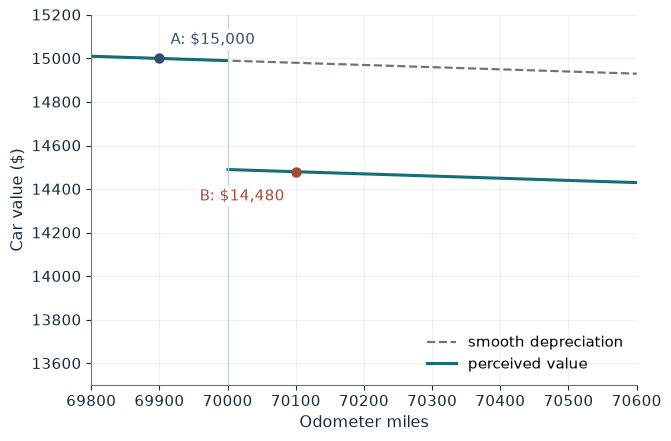

Benchmark value of B  $14,980
Perceived value of B  $14,480
Perceived gap from A  $520
Smooth depreciation   $20
Excess discontinuity  $500

Worked steps:
  1. Extra miles = 70,100 - 69,900 = 200
  2. Benchmark = 15,000 - 200 x 0.10 = 14,980
  3. Perceived = 14,980 - 500 = 14,480
  4. Gap = 15,000 - 14,480 = 520

B has 200 more miles than A, so smooth wear lowers its value by 200 x 0.10 = 20 dollars, to $14,980. B's odometer reads 70 thousand, so the $500 category penalty applies: 14,980 - 500 = $14,480. The perceived gap from A is $520.


In [6]:
show(left_digit_picture(miles_b=70_100, penalty=500))

Change one input, `miles_b`, and hold the others at the book's values:

In [7]:
sweep(left_digit_picture, 'miles_b', [69950, 70100, 70500], {'penalty': 500}, ['Benchmark value of B', 'Perceived value of B', 'Perceived gap from A'])

miles_b | Benchmark value of B | Perceived value of B | Perceived gap from A
69950 | $14,995 | $14,995 | $5
70100 | $14,980 | $14,480 | $520
70500 | $14,940 | $14,440 | $560


Smooth wear justifies only \$20 between the cars; the \$500 category penalty makes the perceived gap \$520. Below 70,000 miles the gap is just the wear.

## 4. Default effect: who the default enrolls

Of 100 workers, 60 gain \$30 from enrolling, 25 lose \$10, and 15 do not act. Switching costs \$20. Prompted, the 15 split 9 favorable and 6 unfavorable.

$$\Delta_i=V_i(E)-V_i(N)=\$30, \qquad 60+9=69$$

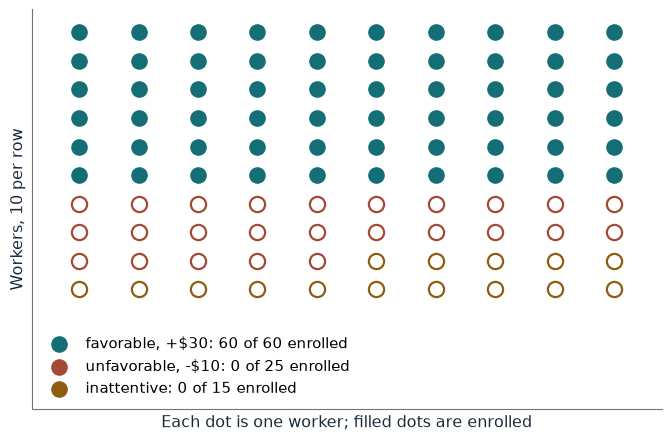

Regime                Opt-in (not enrolled by default)
Switching cost        $20
Favorable enrolled    60 of 60
Unfavorable enrolled  0 of 25
Inattentive enrolled  0 of 15
Enrollment rate       60%

Worked steps:
  1. Favorable: gain 30 > cost 20, so 60 enroll
  2. Unfavorable 25 stay out (enrolling loses 10)
  3. Inattentive 15 keep the default: out
  4. Enrollment = 60 + 0 + 0 = 60, so 60%

With non-enrollment as the default, the favorable workers switch only if $30 exceeds the $20 cost, which it does. The 25 unfavorable and 15 inattentive workers stay out. Enrollment is 60 + 0 + 0 = 60, or 60%.


In [8]:
show(default_picture(regime='opt_in', cost=20))

Change one input, `regime`, and hold the others at the book's values:

In [9]:
sweep(default_picture, 'regime', ['opt_in', 'auto', 'active'], {'cost': 20}, ['Unfavorable enrolled', 'Inattentive enrolled', 'Enrollment rate'])

regime | Unfavorable enrolled | Inattentive enrolled | Enrollment rate
opt_in | 0 of 25 | 0 of 15 | 60%
auto | 25 of 25 | 15 of 15 | 100%
active | 0 of 25 | 9 of 15 | 69%


Enrollment is 60 percent under opt-in, 100 percent under automatic enrollment and 69 percent under active choice, with no change in what any worker gains from enrolling.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

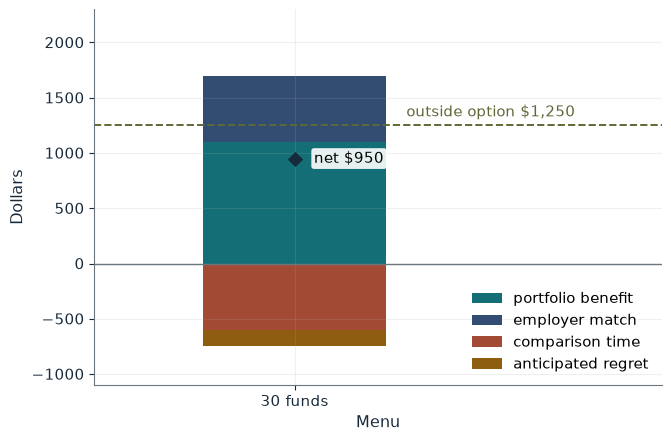

Portfolio benefit     $1,100
Time cost             $600
Anticipated regret    $150
Net enrollment value  $950
Outside option        $1,250
Decision              Maya keeps the cash

Worked steps:
  1. Time cost = 6 x 100 = 600
  2. Net = 1,100 + 600 - 600 - 150 = 950
  3. Compare with the outside option 1,250: Maya keeps the cash

With 30 funds and 6 hours of comparison, time costs 6 x 100 = 600 dollars and the net value is 1,100 + 600 - 600 - 150 = $950, which falls short of the $1,250 outside option. Maya keeps the cash.


In [10]:
show(overload_picture(menu='thirty', hours=6))

## Practice

**1.** With 30 funds and screening regret of \$75, how many comparison hours make Maya exactly indifferent?

<details><summary>Answer</summary>

1,100 + 600 - 100h - 75 = 1,250 gives 100h = 375, so h = 3.75 hours.

</details>

**2.** With B at 70,500 miles and a \$500 penalty, what is the perceived price gap from A?

<details><summary>Answer</summary>

Smooth drop 600 x 0.10 = \$60, plus the \$500 penalty, gives \$560.

</details>

**3.** Under automatic enrollment with a \$5 switching cost, what is enrollment?

<details><summary>Answer</summary>

The 25 unfavorable workers gain \$10 > \$5 by leaving, so enrollment is 60 + 0 + 15 = 75 percent.

</details>